# Bombs: which cards win games, on one scale across sets

The goal is section 4: a list of each set's bombs, with a bomb meaning a card worth a fixed amount of game win rate
in every set, and how often you open or end up with one. Sections 1–3 build up to it:

1. **Card ratings.** Each card's GIH WR above the set average, shrunk toward its rarity.
2. **Deck score.** The average rating of a deck's cards. It predicts wins, but one pp of rating is worth about twice as
   much game win rate in some sets as in others.
3. **Fence bombs.** The usual per-set outlier rule. Because of 2, a fence bomb in one set isn't worth the same as one in
   another.
4. **Bombs by win-rate impact.** Cards worth ≥ 2.5 pp of game win rate per copy, and how often packs and pools have one.
5. **Prince or pauper.** How much of the difference between decks comes from rares, and how that differs from being
   bomb-heavy.
6. **Deep or shallow.** How far down decks have to reach for their last playables.

Abbreviations: **GIH** games in hand (the card was in the opening hand or drawn), **GNS** games not seen (in the deck
but never seen), **WR** win rate, **pp** percentage points, **EB** empirical Bayes (the `_eb` suffix marks a shrunk
column), **IWD** improvement when drawn (GIH WR − GNS WR). All data is 17Lands Premier Draft. Sets are listed in release order, NEO
(Kamigawa: Neon Dynasty, Feb 2022) to MSH (Marvel Super Heroes).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import norm, pearsonr

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import card_metadata
from openlane.deckstrength import aligned, flag
from openlane.games import game_path

OUT = ROOT / "results" / "bombs"
OUT.mkdir(parents=True, exist_ok=True)
SETS = ["NEO", "ONE", "MOM", "WOE", "LCI", "MKM", "OTJ", "BLB", "DSK", "FDN", "DFT", "TDM", "FIN", "EOE", "TLA",
        "ECL", "TMT", "SOS", "MSH"]
MIN_GIH = 200          # games with the card in hand; below this a card is dropped

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True); pl.Config.set_float_precision(2)

polars.config.Config

## 1. Card ratings

A card's rating is its **normalized GIH WR**: its GIH WR minus the set's average game win rate, in pp (`norm`).
17Lands users win about 55% of games, not 50%, and how far above 50% depends on the set, so raw GIH WR isn't
comparable across sets. Subtracting the set average fixes the level. It doesn't change the order of cards within a set,
and it doesn't fix the spread: some sets' ratings are more spread out than others, which matters in section 2.

**Shrinkage.** Per-card estimates are noisy, and the extremes are biased outward, so each card is shrunk toward the
average for its rarity (empirical Bayes, normal–normal). A card's observed value $x_i$ has sampling variance
$s_i^2 = p(1-p)/n_i$. Within a rarity the true values are assumed $\sim N(\mu_r, \tau_r^2)$, with $\mu_r$ the
precision-weighted mean and $\tau_r^2 = \max(\mathrm{Var}(x) - \overline{s^2}, 0.25\,\mathrm{pp}^2)$, and the shrunk
rating (`norm_eb`) is $\mu_r + \frac{\tau_r^2}{\tau_r^2 + s_i^2}(x_i - \mu_r)$. Mythics average several pp above commons,
so a prior shared across rarities would over-shrink the bombs.

Basic lands are dropped, and so are cards with fewer than `MIN_GIH` games in GIH or GNS. IWD (GIH WR − GNS WR) is
computed and cached too (`iwd_eb`, used by `consensus_bombs.ipynb`), but it isn't used here. As a deck rating it
predicts total wins worse than GIH WR on all 19 sets (README, "Bombs and deck card strength"). Per-card tables are cached to
`results/bombs/{set}.PremierDraft.cards.parquet`.

In [2]:
BASICS = ["Plains", "Island", "Swamp", "Mountain", "Forest"]


def eb_shrink(x, se2, groups):
    out = np.empty_like(x)
    for g in np.unique(groups):
        m = groups == g
        w = 1 / se2[m]
        mu = (w * x[m]).sum() / w.sum()
        tau2 = max(x[m].var() - se2[m].mean(), 0.25)
        out[m] = mu + tau2 / (tau2 + se2[m]) * (x[m] - mu)
    return out


def rate_cards(g, s, names):
    # per-card ratings on the games in g, in pp: norm = GIH WR above g's average win rate, iwd = GIH WR - GNS WR
    won = flag(g["won"])
    seen = (aligned(g, "opening_hand_", names) + aligned(g, "drawn_", names)) > 0
    unseen = (aligned(g, "deck_", names) > 0) & ~seen
    base = won.mean()
    meta = card_metadata(names, s)
    df = pl.DataFrame({"name": names, "rarity": meta["rarity"],
                       "n_gih": seen.sum(0).astype(np.int64), "n_gns": unseen.sum(0).astype(np.int64),
                       "w_gih": seen[won].sum(0).astype(np.int64), "w_gns": unseen[won].sum(0).astype(np.int64)})
    df = (df.filter((pl.col("n_gih") >= MIN_GIH) & (pl.col("n_gns") >= MIN_GIH) & (pl.col("rarity") != "basic")
                    & ~pl.col("name").is_in(BASICS))
          .with_columns((pl.col("w_gih") / pl.col("n_gih")).alias("gih_wr"), (pl.col("w_gns") / pl.col("n_gns")).alias("gns_wr"))
          .drop("w_gih", "w_gns"))
    p, q = df["gih_wr"].to_numpy(), df["gns_wr"].to_numpy()
    se2 = p * (1 - p) / df["n_gih"].to_numpy() * 1e4
    se2_gns = q * (1 - q) / df["n_gns"].to_numpy() * 1e4
    x, iwd, rarity = (p - base) * 100, (p - q) * 100, df["rarity"].to_numpy()
    return df.with_columns(pl.lit(float(base) * 100).alias("set_wr"), pl.Series("norm", x),
                           pl.Series("norm_eb", eb_shrink(x, se2, rarity)), pl.Series("iwd", iwd),
                           pl.Series("iwd_eb", eb_shrink(iwd, se2 + se2_gns, rarity)))


def card_table(s, event="PremierDraft"):
    path = OUT / f"{s}.{event}.cards.parquet"
    if path.exists() and "iwd_eb" in pl.read_parquet_schema(path):
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    df = rate_cards(g, s, names).with_columns(
        pl.lit(s).alias("set"), pl.lit(event).alias("event"), pl.lit(g.height).alias("n_games"),
        pl.lit(str(g["draft_time"].min())[:10]).alias("first_day"))
    df.write_parquet(path)
    return df


cards = pl.concat([card_table(s) for s in SETS], how="diagonal")
(cards.group_by("set").agg(pl.first("first_day").alias("first day"), pl.first("n_games").alias("games"),
                           pl.first("set_wr").alias("set WR %"), pl.len().alias("cards"))
 .sort("first day"))

set,first day,games,set WR %,cards
str,str,i32,f64,u32
"""NEO""","""2022-02-10""",630450,55.60,280
"""ONE""","""2023-02-02""",583077,54.75,260
"""MOM""","""2023-04-13""",1246850,54.76,341
"""WOE""","""2023-08-31""",1024028,55.20,307
"""LCI""","""2023-11-09""",823614,55.34,285
"""MKM""","""2024-02-06""",964377,54.98,303
"""OTJ""","""2024-04-16""",1172393,54.14,368
"""BLB""","""2024-07-30""",931230,54.60,268
"""DSK""","""2024-09-24""",1011949,54.48,275


## 2. Deck score: average rating of the deck's cards

For every game, the deck's **score** is the mean `norm_eb` of the cards in its main deck, weighted by copies, with
basics left out. If a card's rating came from the same games it's scoring, each deck's own result would leak into its
score, so the scores are **cross-fitted**: drafts (draft_ids) are split into two random halves, and each half is scored
with ratings from the other half only. Only drafts where every game has ≥ 90% of its nonbasic cards rated (`cover`)
are kept. A drafter can rebuild between games, so the score is per game. Drafter-level numbers average it over that
drafter's games. Per-game scores are cached to `results/bombs/{set}.PremierDraft.decks.parquet`.

The plot shows game win rate in bins of deck score, both in pp relative to the set average. The thin lines are
individual sets and the thick line pools all sets. Bins are a quarter of an SD of deck score wide.

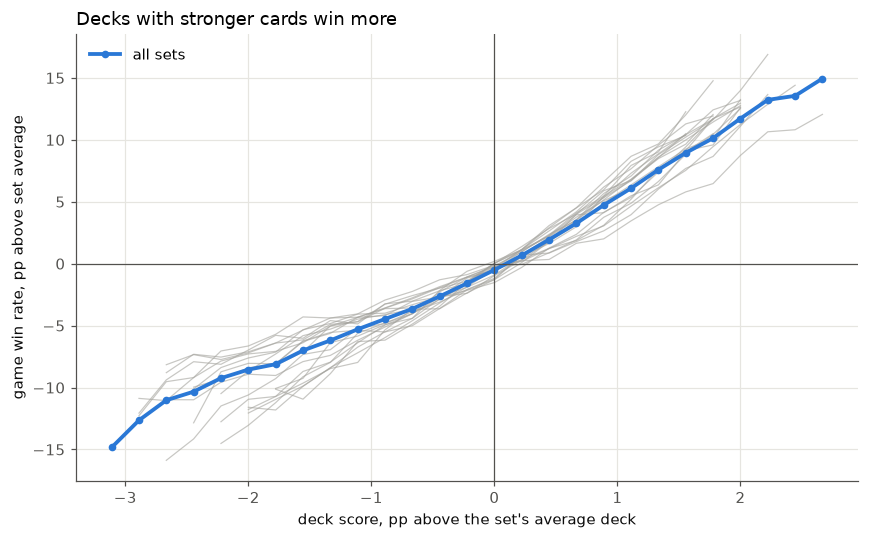

games kept: 14,162,130


In [3]:
def deck_scores(s, event="PremierDraft"):
    path = OUT / f"{s}.{event}.decks.parquet"
    if path.exists() and "score_gih" in pl.read_parquet_schema(path):
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    idx = {n: j for j, n in enumerate(names)}
    nonbasic = ~np.isin(names, BASICS)
    deck = aligned(g, "deck_", names).astype(np.float32)
    half = g["draft_id"].hash(seed=7).to_numpy() % 2
    score, cover = np.full(g.height, np.nan), np.zeros(g.height)
    for h in (0, 1):
        r = rate_cards(g.filter(pl.Series(half != h)), s, names)   # ratings from the other half
        j, m = [idx[n] for n in r["name"]], half == h
        d = deck[m][:, j]
        k = d.sum(1)
        score[m] = d @ r["norm_eb"].to_numpy() / np.maximum(k, 1)
        cover[m] = k / np.maximum(deck[m][:, nonbasic].sum(1), 1)
    out = pl.DataFrame({"draft_id": g["draft_id"], "won": flag(g["won"]), "cover": cover, "score_gih": score})
    out.write_parquet(path)
    return out


games = (pl.concat([deck_scores(s).select("draft_id", "won", "cover", pl.col("score_gih").alias("score"))
                    .with_columns(pl.lit(s).alias("set")) for s in SETS])
         .filter((pl.col("cover").min() >= 0.9).over("set", "draft_id")))
games = games.with_columns(((pl.col("won").cast(pl.Float64) - pl.col("won").cast(pl.Float64).mean().over("set")) * 100)
                           .alias("won_c"), (pl.col("score") - pl.col("score").mean().over("set")).alias("score_c"))

w = 0.25 * games["score_c"].std()
g = games.with_columns(((pl.col("score_c") / w).round() * w).alias("bin"))
fig, ax = plt.subplots(figsize=(8, 5))
for s in SETS:
    b = g.filter(pl.col("set") == s).group_by("bin").agg(pl.col("won_c").mean(), pl.len()).filter(pl.col("len") >= 2000).sort("bin")
    ax.plot(b["bin"], b["won_c"], color=GRAY, lw=0.8, alpha=0.6)
b = g.group_by("bin").agg(pl.col("won_c").mean(), pl.len()).filter(pl.col("len") >= 5000).sort("bin")
ax.plot(b["bin"], b["won_c"], "o-", color=BLUE, lw=2.5, ms=4, label="all sets")
ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("deck score, pp above the set's average deck"); ax.set_ylabel("game win rate, pp above set average")
ax.set_title("Decks with stronger cards win more", loc="left"); ax.legend()
plt.tight_layout(); plt.show()
print(f"games kept: {games.height:,}")

### 2a. Per set

Saved as `deck_score_summary_gih.csv`.

* **slope**: pp of game win rate per +1 pp of deck score (linear regression on games).
* **sd drafter**: SD of the drafter-average score (drafters with ≥ 3 games).
* **sd true WR**: SD of drafters' true win rates, i.e. the observed SD of per-drafter win rate with the binomial noise of
  their few games subtracted.
* **share explained**: Var(slope × drafter score) / Var(true WR), the share of the real spread in drafter win rates
  that deck card strength accounts for.
* **1 SD gap**: slope × sd drafter, the win rate gap between an average deck and one 1 SD better.

In [4]:
rows = []
for s in SETS:
    g = games.filter(pl.col("set") == s)
    x, y = g["score"].to_numpy(), g["won"].to_numpy().astype(np.float64)
    slope = np.cov(x, y)[0, 1] / x.var() * 100
    dr = (g.group_by("draft_id").agg(pl.col("score").mean(), pl.col("won").cast(pl.Float64).mean().alias("wr"),
                                     pl.len().alias("n"))
          .filter(pl.col("n") >= 3))
    ds, wr, n = dr["score"].to_numpy(), dr["wr"].to_numpy(), dr["n"].to_numpy()
    var_true = wr.var() - np.mean(wr.mean() * (1 - wr.mean()) / n)
    rows.append({"set": s, "games": g.height, "drafters": dr.height, "slope": slope, "sd drafter": ds.std(),
                 "sd true WR": np.sqrt(var_true) * 100, "share explained": (slope * ds.std()) ** 2 / (var_true * 1e4),
                 "1 SD gap": slope * ds.std()})
per_set = pl.DataFrame(rows)
per_set.write_csv(OUT / "deck_score_summary_gih.csv")
display(per_set)
print("median over sets:", {k: round(float(per_set[k].median()), 3) for k in per_set.columns[3:]})

set,games,drafters,slope,sd drafter,sd true WR,share explained,1 SD gap
str,i64,i64,f64,f64,f64,f64,f64
"""NEO""",630450,102334,4.36,0.99,9.09,0.22,4.29
"""ONE""",583066,96118,3.60,1.29,8.73,0.28,4.63
"""MOM""",1246850,206175,4.49,1.00,8.96,0.25,4.49
"""WOE""",1023993,167996,5.38,0.85,8.81,0.27,4.59
"""LCI""",823611,134913,5.76,0.95,8.75,0.39,5.46
"""MKM""",964361,158520,6.05,0.80,8.55,0.32,4.82
"""OTJ""",1172389,194700,4.28,0.98,8.61,0.24,4.21
"""BLB""",931230,153466,4.72,0.84,8.43,0.22,3.97
"""DSK""",1011943,166909,6.99,0.72,8.51,0.35,5.06


median over sets: {'slope': 5.381, 'sd drafter': 0.853, 'sd true WR': 8.449, 'share explained': 0.331, '1 SD gap': 4.632}


### 2b. A pp of rating isn't worth the same in every set

The slope runs from about 3.6 to 7.0 pp of win rate per pp of rating, and it's lowest where decks look most different
(high `sd drafter`). The two vary together: the 1 SD gap stays at 3.7–5.5 pp across sets while each factor varies
much more.

Why the slope shrinks when the spread grows:

* **Not a wider opponent pool.** In a probit model of one game, $P(\mathrm{win}) = \Phi(s_\mathrm{you} - s_\mathrm{opp})$
  with $s_\mathrm{opp} \sim N(0, \sigma_\mathrm{pool}^2)$, a wider pool flattens the slope by
  $1/\sqrt{1 + \sigma_\mathrm{pool}^2}$. In probit units (pp ÷ 0.399), even the whole true WR spread (about 8.4 pp, so
  about 0.21) gives a factor of 0.975–0.983. That's 1–2%, nearly the same in every set, against a 2× range in slopes.
  A single game is mostly noise, so win rates sit on the nearly straight middle of the S-curve.
* **Matchmaking can't be tested.** Premier Draft pairs players of similar rank and record, so strong decks meet
  strong decks more often. That could matter, but the game data doesn't include the opponent's deck.
* **The likely cause: the rating scale stretches from set to set.** Part of a card's GIH WR spread isn't card power. It
  comes from which players pick the card, which games it gets seen in, and leftover noise. When there's more of
  that, decks look more different without being more different, and each pp of rating is worth less.

So rating units can't be compared across sets, and neither can any bomb rule written in them. That's the problem
section 3 runs into and section 4 fixes.

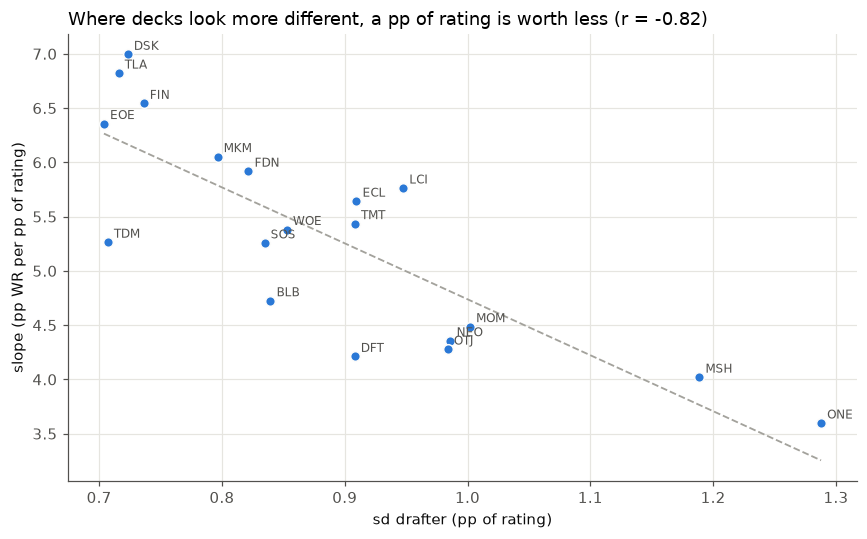

In [5]:
d = per_set
sd, sl = d["sd drafter"].to_numpy(), d["slope"].to_numpy()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sd, sl, color=BLUE, s=40, edgecolor=SURFACE, lw=1, zorder=3)
for s, xi, yi in zip(d["set"], sd, sl):
    ax.annotate(s, (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=8, color=MUTED)
b, a = np.polyfit(sd, sl, 1)
xx = np.linspace(sd.min(), sd.max(), 2)
ax.plot(xx, a + b * xx, color=GRAY, lw=1.2, ls="--")
ax.set_xlabel("sd drafter (pp of rating)"); ax.set_ylabel("slope (pp WR per pp of rating)")
ax.set_title(f"Where decks look more different, a pp of rating is worth less (r = {pearsonr(sd, sl)[0]:+.2f})", loc="left")
plt.tight_layout(); plt.show()

## 3. Fence bombs: the per-set outlier rule

The usual way to call a card a bomb is to call it an upper outlier of its set. Within each set, a card is a **fence bomb** if
its rating is above the **Tukey upper fence**, Q3 + 1.5 × IQR. On a robust z scale, z = (rating − median) /
(IQR / 1.349), the fence sits at **z = 2.70**. If ratings were normal, only 0.35% of cards (about one per set)
would clear it. The plot shows the right tail is fatter than that, so the bombs really do stand apart from the rest of
their set.

But the fence uses the set's own spread as its yardstick, and section 2b shows that spread is on a different scale in
each set. The per-set fence in pp is shown in the table below.

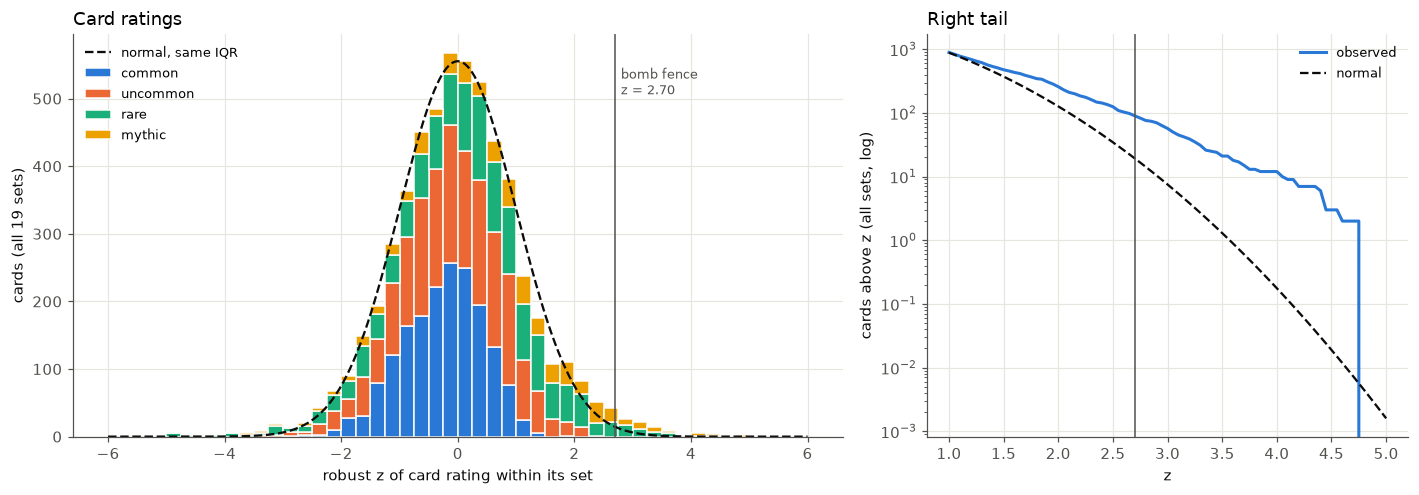

cards: 5568, above the fence: 90 (normal would give 19)


set,cards,fence (pp),bombs,C,U,R,M,cards (rating pp)
str,i64,f64,i64,i64,i64,i64,i64,str
"""NEO""",280,9.63,5,0,0,3,2,"""Jugan Defends the Temple +12.7, Fable of the Mirror-Breaker +11.6, The Wandering Emperor +11.2, Inventive Iteration +10.4, Farewell +10.4"""
"""ONE""",260,10.57,2,0,0,1,1,"""Nissa, Ascended Animist +12.1, Migloz, Maze Crusher +12.0"""
"""MOM""",341,8.80,7,0,0,5,2,"""Elesh Norn, Grand Cenobite +12.5, Sunfall +12.2, Chrome Host Seedshark +10.1, Boon-Bringer Valkyrie +9.5, Zephyr Singer +9.0, Sheoldred +9.0, Glissa, Herald of Predation +8.8"""
"""WOE""",307,9.24,2,0,0,1,1,"""Gruff Triplets +13.7, Virtue of Persistence +11.1"""
"""LCI""",285,8.92,10,0,0,7,3,"""Bonehoard Dracosaur +14.9, Aclazotz, Deepest Betrayal +13.5, Palani's Hatcher +12.0, Kitesail Larcenist +10.2, Unstable Glyphbridge +9.9, Magmatic Galleon +9.9, Sanguine Evangelist +9.8, Huatli, Poet of Unity +9.7, Breeches, Eager Pillager +9.5, Sentinel of the Nameless City +9.1"""
"""MKM""",303,8.56,3,0,0,1,2,"""Aurelia's Vindicator +13.3, Izoni, Center of the Web +10.1, Agrus Kos, Spirit of Justice +8.7"""
"""OTJ""",368,8.87,8,0,0,2,6,"""Bonny Pall, Clearcutter +12.1, Railway Brawler +11.0, Overwhelming Forces +10.5, Oko, Thief of Crowns +10.0, Vaultborn Tyrant +9.9, Rakdos, the Muscle +9.7, Roxanne, Starfall Savant +9.5, Bristly Bill, Spine Sower +9.3"""
"""BLB""",268,9.13,6,0,0,4,2,"""Season of Loss +11.0, Sword of Fire and Ice +10.1, Dreamdew Entrancer +10.0, Valley Questcaller +9.7, Mabel, Heir to Cragflame +9.3, Fecund Greenshell +9.3"""
"""DSK""",275,8.47,8,0,0,4,4,"""Overlord of the Mistmoors +13.6, Valgavoth's Onslaught +11.4, Unholy Annex // Ritual Chamber +10.2, The Swarmweaver +9.9, Ghostly Dancers +9.8, Overlord of the Boilerbilges +9.5, Overlord of the Floodpits +8.6, Tyvar, the Pummeler +8.5"""


In [6]:
FENCE_Z = 0.6745 + 1.5 * 1.349   # Q3 + 1.5 IQR, in units of IQR / 1.349
RARITIES = ["common", "uncommon", "rare", "mythic"]
R_COLOR = dict(zip(RARITIES, [BLUE, ORANGE, AQUA, YELLOW]))

r = (cards.with_columns(pl.col("norm_eb").alias("rating"))
     .with_columns(pl.col("rating").median().over("set").alias("med"),
                   ((pl.col("rating").quantile(0.75) - pl.col("rating").quantile(0.25)) / 1.349).over("set").alias("sig"))
     .with_columns(((pl.col("rating") - pl.col("med")) / pl.col("sig")).alias("z"))
     .with_columns((pl.col("z") > FENCE_Z).alias("bomb")))
z = r["z"].to_numpy()

bins = np.arange(-6, 6.01, 0.25)
xs, zz = np.linspace(-6, 6, 400), np.linspace(1, 5, 81)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
bottom = np.zeros(len(bins) - 1)
for k in RARITIES:
    h, _ = np.histogram(z[r["rarity"].to_numpy() == k], bins)
    ax.bar(bins[:-1], h, width=0.25, align="edge", bottom=bottom, color=R_COLOR[k], edgecolor=SURFACE, lw=1, label=k)
    bottom += h
ax.plot(xs, norm.pdf(xs) * len(z) * 0.25, color=INK, lw=1.5, ls="--", label="normal, same IQR")
ax.axvline(FENCE_Z, color=MUTED, lw=1)
ax.text(FENCE_Z + 0.1, ax.get_ylim()[1] * 0.92, "bomb fence\nz = 2.70", fontsize=8.5, color=MUTED, va="top")
ax.set_xlabel("robust z of card rating within its set"); ax.set_ylabel("cards (all 19 sets)")
ax.set_title("Card ratings", loc="left"); ax.legend(fontsize=8.5)
ax = axes[1]
ax.semilogy(zz, [(z > t).sum() for t in zz], color=BLUE, label="observed")
ax.semilogy(zz, norm.sf(zz) * len(z), color=INK, ls="--", lw=1.5, label="normal")
ax.axvline(FENCE_Z, color=MUTED, lw=1)
ax.set_xlabel("z"); ax.set_ylabel("cards above z (all sets, log)")
ax.set_title("Right tail", loc="left"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
print(f"cards: {len(z)}, above the fence: {(z > FENCE_Z).sum()} (normal would give {norm.sf(FENCE_Z) * len(z):.0f})")

bombs = r.filter(pl.col("bomb"))
fences = r.group_by("set").agg((pl.col("med") + FENCE_Z * pl.col("sig")).first().alias("fence"), pl.len().alias("cards"))
rows = []
for s in SETS:
    b = bombs.filter(pl.col("set") == s).sort("rating", descending=True)
    f = fences.filter(pl.col("set") == s)
    rows.append({"set": s, "cards": f["cards"][0], "fence (pp)": f["fence"][0], "bombs": b.height,
                 **{k[0].upper(): (b["rarity"] == k).sum() for k in RARITIES},
                 "cards (rating pp)": ", ".join(f"{n} {v:+.1f}" for n, v in zip(b["name"], b["rating"]))})
with pl.Config(fmt_str_lengths=400, tbl_width_chars=600):
    display(pl.DataFrame(rows))

## 4. Bombs by win-rate impact

Section 3's fence is relative to each set's own ratings. Section 2b shows those ratings are on a different scale in
every set: per pp of rating, the deck-score slope runs from 3.6 (ONE) to 7.0 (DSK). So a fence bomb in one set isn't
worth the same as a fence bomb in another. This section uses one yardstick for every set: **what the card is worth in
game win rate**.

**Definition.** A card is a **bomb** if one copy in the deck is worth **≥ 2.5 pp of game win rate** compared with an
average card of the same deck.

That number, `impact`, comes from `scripts/card_impact.py` (`results/bombs/card_impact.csv`). The method and its checks
are in `notebooks/card_impact.ipynb`. In short, per set and per card, a linear regression on Premier Draft games of
`won` on:

* the copies of the card in the deck,
* the deck score with that card left out (section 2's cross-fitted GIH WR score), so the card is compared with an
  average card of the same deck,
* the drafter's overall game win rate bucket, so "good drafters take this card" doesn't count as card strength,
* main colors, play/draw, and the number of rated cards.

Standard errors are clustered by draft. Estimates are shrunk toward the set × rarity mean (bonus-sheet reprints toward
one pooled bonus-sheet mean), and cards in fewer than 500 decks are left out.

Why 2.5 pp: a set's 5th best card is worth a median of +3.1 pp, its 10th best +2.3. At ≥ 2.5 pp, 72% of the cards the
community called bombs both before and after release clear the bar, against 2% of other rares and mythics. The value of
a set's top cards doesn't track the slope or `sd drafter` (`card_impact.ipynb` section 3c). So differences in
bomb counts here are differences between sets, not between rating scales.

In [7]:
IMPACT_BOMB = 2.5   # pp of game win rate per copy
imp = pl.read_csv(OUT / "card_impact.csv").rename({"impact_eb": "impact"})
ibombs = imp.filter(pl.col("impact") >= IMPACT_BOMB)
fence_gih = bombs
rows = []
for s in SETS:
    b = ibombs.filter(pl.col("set") == s).sort("impact", descending=True)
    fn = set(fence_gih.filter(pl.col("set") == s)["name"])
    rows.append({"set": s, "bombs": b.height, **{k[0].upper(): (b["rarity"] == k).sum() for k in RARITIES},
                 "also fence (GIH)": len(fn & set(b["name"])), "fence only": len(fn - set(b["name"])),
                 "cards (pp game WR)": ", ".join(f"{n} {v:+.1f}" for n, v in zip(b["name"], b["impact"]))})
impact_tbl = pl.DataFrame(rows)
ibombs.select("set", "name", "rarity", "impact", pl.col("se_B").alias("se"), "games_in_deck", "is_bonus").write_csv(
    OUT / "bombs_impact.csv")
with pl.Config(fmt_str_lengths=500, tbl_width_chars=700):
    display(impact_tbl)
print(f"bombs: {ibombs.height} (median {impact_tbl['bombs'].median():.0f} per set, range {impact_tbl['bombs'].min()} "
      f"to {impact_tbl['bombs'].max()}); by rarity:", dict(ibombs["rarity"].value_counts().iter_rows()))
print(f"GIH WR fence bombs: {fence_gih.height}; in both lists: {int(impact_tbl['also fence (GIH)'].sum())}; "
      f"fence only: {int(impact_tbl['fence only'].sum())}")

set,bombs,C,U,R,M,also fence (GIH),fence only,cards (pp game WR)
str,i64,i64,i64,i64,i64,i64,i64,str
"""NEO""",7,0,0,5,2,5,0,"""Jugan Defends the Temple +4.9, The Wandering Emperor +3.5, Inventive Iteration +3.4, Farewell +3.1, Fable of the Mirror-Breaker +3.1, Kami of Transience +2.8, Reckoner Bankbuster +2.6"""
"""ONE""",8,0,0,5,3,2,0,"""Nissa, Ascended Animist +3.8, Sheoldred, the Apocalypse +3.7, Migloz, Maze Crusher +3.2, Blue Sun's Twilight +3.1, The Eternal Wanderer +3.1, Archfiend of the Dross +2.8, White Sun's Twilight +2.6, Elesh Norn, Mother of Machines +2.5"""
"""MOM""",12,0,0,7,5,7,0,"""Sunfall +4.1, Elesh Norn, Grand Cenobite +3.8, Sheoldred +3.6, Vorinclex +3.4, Chrome Host Seedshark +3.2, Zephyr Singer +3.1, Glissa, Herald of Predation +3.1, Boon-Bringer Valkyrie +3.0, Breach the Multiverse +3.0, Chandra, Hope's Beacon +2.7, Invasion of New Phyrexia +2.6, Etali, Primal Conqueror +2.6"""
"""WOE""",5,0,0,4,1,2,0,"""Gruff Triplets +4.9, Virtue of Persistence +3.7, Horned Loch-Whale +3.3, Redcap Gutter-Dweller +2.7, Lord Skitter, Sewer King +2.6"""
"""LCI""",14,0,0,10,4,10,0,"""Bonehoard Dracosaur +5.4, Aclazotz, Deepest Betrayal +5.3, Kitesail Larcenist +3.9, Sanguine Evangelist +3.8, Breeches, Eager Pillager +3.7, Unstable Glyphbridge +3.6, Palani's Hatcher +3.6, Sentinel of the Nameless City +3.4, Huatli, Poet of Unity +3.1, Magmatic Galleon +3.1, Preacher of the Schism +3.0, Ojer Kaslem, Deepest Growth +3.0, Pugnacious Hammerskull +2.7, Trumpeting Carnosaur +2.5"""
"""MKM""",8,0,0,5,3,3,0,"""Aurelia's Vindicator +4.9, Izoni, Center of the Web +3.3, Vein Ripper +3.2, Smuggler's Copter +3.0, Cryptic Coat +3.0, Ezrim, Agency Chief +2.6, Steamcore Scholar +2.6, Agrus Kos, Spirit of Justice +2.5"""
"""OTJ""",10,0,0,2,8,8,0,"""Bonny Pall, Clearcutter +4.0, Railway Brawler +3.4, Overwhelming Forces +3.3, Bristly Bill, Spine Sower +3.3, Oko, Thief of Crowns +3.1, Vaultborn Tyrant +3.1, Rakdos, the Muscle +3.0, Roxanne, Starfall Savant +2.7, Hostile Investigator +2.7, Bristlebud Farmer +2.6"""
"""BLB""",12,0,0,8,4,6,0,"""Valley Questcaller +3.5, Sword of Fire and Ice +3.1, Maha, Its Feathers Night +3.1, Season of Loss +3.1, Manifold Mouse +3.1, Mabel, Heir to Cragflame +2.9, Dreamdew Entrancer +2.8, Gev, Scaled Scorch +2.7, Fecund Greenshell +2.7, Innkeeper's Talent +2.6, Ygra, Eater of All +2.6, Zoraline, Cosmos Caller +2.5"""
"""DSK""",10,0,0,4,6,8,0,"""Overlord of the Mistmoors +4.5, Overlord of the Boilerbilges +3.8, Tyvar, the Pummeler +3.6, Valgavoth's Onslaught +3.5, Unholy Annex // Ritual Chamber +3.5, Overlord of the Floodpits +3.2, Ghostly Dancers +3.1, The Swarmweaver +3.0, Overlord of the Balemurk +2.9, Screaming Nemesis +2.5"""


bombs: 153 (median 8 per set, range 3 to 14); by rarity: {'mythic': 70, 'rare': 83}
GIH WR fence bombs: 90; in both lists: 85; fence only: 5


### 4a. How often do you see one?

From the 17Lands draft logs (no pick data for NEO or ONE), saved as `bomb_frequency_impact.csv`:

* `P(pack)`: share of freshly opened packs (pick 1 of each round, a whole 14-card pack) with at least one bomb.
* `P(you open)`: chance that at least one of your own 3 packs has a bomb, $1 - (1 - P_\text{pack})^3$.
* `P(pod)`: chance that at least one of the table's 24 packs has a bomb, $1 - (1 - P_\text{pack})^{24}$.
* `per pod`: expected bombs opened at an 8-player table.
* `P(pool ≥1)`, `P(pool ≥2)`: share of complete drafts whose 42 picks include at least one or two bombs. These are
  17Lands users, who are above-average drafters and take bombs when they see them.
* `capture`: `mean in pool` ÷ (`per pod` / 8). That's the bombs a 17Lands user ends up with, relative to an even share of the
  bombs opened at the table. Above 1 means they end up with more than their share. Where it's well below 1, bombs
  opened at the table mostly end up with other drafters. The data doesn't say why: those drafters may have rated
  the card higher than 17Lands users did, or the card may sit in a pack slot the data counts differently.

In [8]:
def bomb_freq(s, names):
    # how often set s's opened packs and final pools contain a card in `names`
    lf = pl.scan_parquet(ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet")
    names = set(names)
    cols = [f"pack_card_{n}" for n in names if f"pack_card_{n}" in lf.collect_schema().names()]
    n = lf.group_by("draft_id").len()
    full = n.filter(pl.col("len") == pl.col("len").mode().first()).select("draft_id")
    packs = (lf.filter(pl.col("pick_number") == 0)
             .select(pl.sum_horizontal(cols).alias("b") if cols else pl.lit(0).alias("b")).collect()["b"].to_numpy())
    pool = (lf.join(full, on="draft_id").group_by("draft_id").agg(pl.col("pick").is_in(list(names)).sum().alias("b"))
            .collect()["b"].to_numpy())
    return {"set": s, "bombs": len(names), "P(pack)": (packs > 0).mean(), "per pod": packs.mean() * 24,
            "P(pool ≥1)": (pool >= 1).mean(), "P(pool ≥2)": (pool >= 2).mean(), "mean in pool": pool.mean(),
            "drafts": len(pool)}


DRAFT_SETS = [s for s in SETS if (ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet").exists()]
freq_imp = pl.DataFrame([bomb_freq(s, ibombs.filter(pl.col("set") == s)["name"]) for s in DRAFT_SETS])
freq_imp = freq_imp.with_columns((1 - (1 - pl.col("P(pack)")) ** 3).alias("P(you open)"),
                                 (1 - (1 - pl.col("P(pack)")) ** 24).alias("P(pod)"),
                                 (pl.col("mean in pool") / (pl.col("per pod") / 8)).alias("capture")).select(
    "set", "bombs", "P(pack)", "P(you open)", "P(pod)", "per pod", "P(pool ≥1)", "P(pool ≥2)", "mean in pool", "capture",
    "drafts")
freq_imp.write_csv(OUT / "bomb_frequency_impact.csv")
with pl.Config(float_precision=3):
    display(freq_imp)
print("median over sets:", {k: round(float(freq_imp[k].median()), 3) for k in freq_imp.columns[1:-1]})
r_ = np.corrcoef(freq_imp["bombs"], freq_imp["P(pool ≥1)"])[0, 1]
print(f"across sets, r(bomb count, P(pool ≥1)) = {r_:.2f}")

set,bombs,P(pack),P(you open),P(pod),per pod,P(pool ≥1),P(pool ≥2),mean in pool,capture,drafts
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""MOM""",12,0.133,0.349,0.968,3.211,0.367,0.063,0.436,1.086,205437
"""WOE""",5,0.064,0.181,0.797,1.544,0.194,0.015,0.210,1.086,165792
"""LCI""",14,0.159,0.405,0.984,3.818,0.405,0.081,0.497,1.041,134970
"""MKM""",8,0.097,0.264,0.914,2.376,0.277,0.040,0.320,1.079,157553
"""OTJ""",10,0.084,0.231,0.878,2.068,0.252,0.031,0.286,1.106,195312
"""BLB""",12,0.166,0.421,0.987,4.102,0.418,0.092,0.525,1.023,154585
"""DSK""",10,0.122,0.324,0.957,3.013,0.338,0.057,0.401,1.064,167672
"""FDN""",3,0.030,0.086,0.514,0.713,0.097,0.005,0.102,1.142,130935
"""DFT""",6,0.066,0.185,0.806,1.600,0.192,0.018,0.211,1.053,141166


median over sets: {'bombs': 8.0, 'P(pack)': 0.092, 'P(you open)': 0.25, 'P(pod)': 0.9, 'per pod': 2.228, 'P(pool ≥1)': 0.277, 'P(pool ≥2)': 0.037, 'mean in pool': 0.318, 'capture': 1.086}
across sets, r(bomb count, P(pool ≥1)) = 0.93


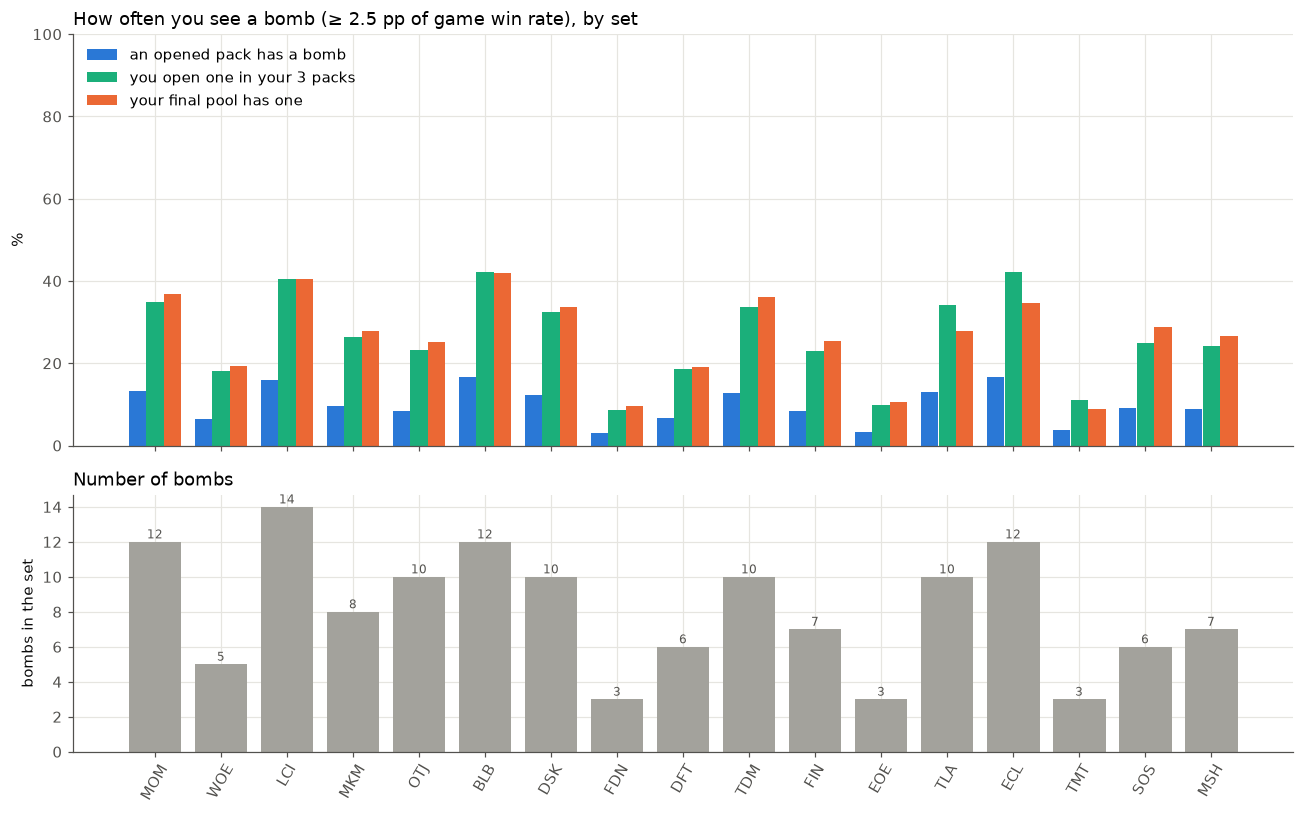

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
x = np.arange(freq_imp.height)
ax = axes[0]
ax.bar(x - 0.27, freq_imp["P(pack)"] * 100, width=0.26, color=BLUE, label="an opened pack has a bomb")
ax.bar(x, freq_imp["P(you open)"] * 100, width=0.26, color=AQUA, label="you open one in your 3 packs")
ax.bar(x + 0.27, freq_imp["P(pool ≥1)"] * 100, width=0.26, color=ORANGE, label="your final pool has one")
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.legend(loc="upper left")
ax.set_title(f"How often you see a bomb (≥ {IMPACT_BOMB} pp of game win rate), by set", loc="left")
ax = axes[1]
ax.bar(x, freq_imp["bombs"], color=GRAY)
for xi, v in zip(x, freq_imp["bombs"]):
    ax.text(xi, v + 0.2, str(v), ha="center", fontsize=8, color=MUTED)
ax.set_ylabel("bombs in the set"); ax.set_title("Number of bombs", loc="left")
axes[1].set_xticks(x, freq_imp["set"], rotation=60)
plt.tight_layout(); plt.show()

### 4b. Impact vs GIH WR

How closely does `impact` (pp of game win rate per copy, from the regression) track the shrunk GIH WR rating
(`norm_eb`, section 1)? The correlation is computed within each set, since the rating scale differs between sets (2b),
then pooled, and by rarity. `slope` is pp of impact per pp of rating.

set,cards,pearson r,spearman ρ,slope
str,i64,f64,f64,f64
"""NEO""",280,0.74,0.62,0.19
"""ONE""",260,0.81,0.74,0.19
"""MOM""",341,0.80,0.69,0.22
"""WOE""",307,0.75,0.69,0.16
"""LCI""",285,0.83,0.71,0.23
"""MKM""",301,0.82,0.75,0.20
"""OTJ""",368,0.80,0.73,0.20
"""BLB""",267,0.83,0.82,0.23
"""DSK""",274,0.84,0.78,0.24


median over sets: {'pearson r': 0.79, 'spearman ρ': 0.69, 'slope': 0.2}
pooled: pearson r = 0.78, spearman ρ = 0.70
pearson r by rarity: {'common': 0.39, 'uncommon': 0.68, 'rare': 0.86, 'mythic': 0.88}


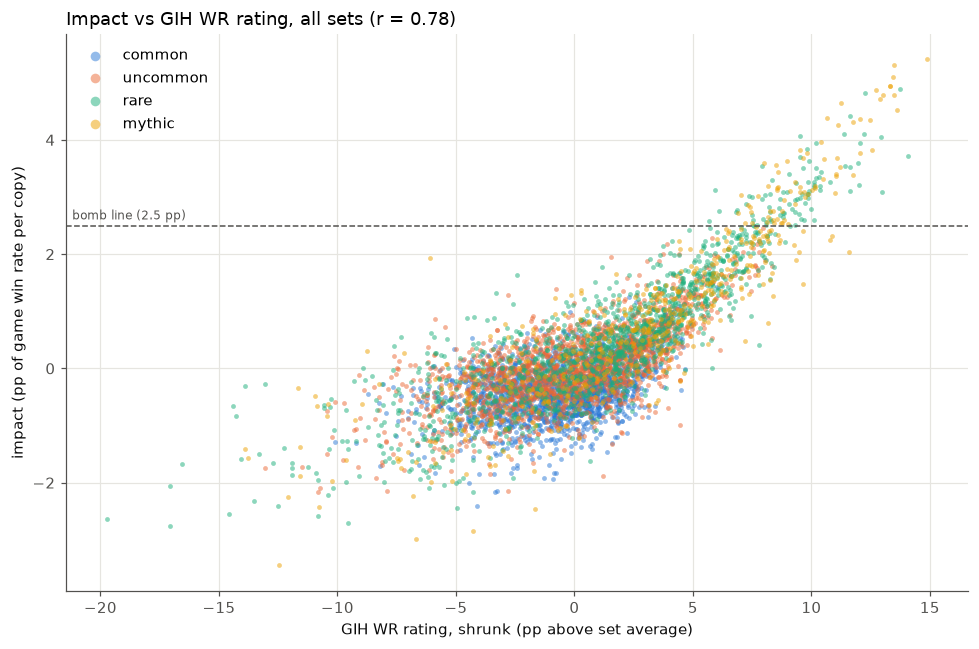

In [10]:
from scipy.stats import spearmanr

rows = []
for s in SETS:
    d = imp.filter(pl.col("set") == s)
    x, y = d["norm_eb"].to_numpy(), d["impact"].to_numpy()
    rows.append({"set": s, "cards": d.height, "pearson r": pearsonr(x, y)[0], "spearman ρ": spearmanr(x, y)[0],
                 "slope": np.polyfit(x, y, 1)[0]})
corr_tbl = pl.DataFrame(rows)
display(corr_tbl)
print("median over sets:", {k: round(float(corr_tbl[k].median()), 2) for k in ["pearson r", "spearman ρ", "slope"]})
x, y = imp["norm_eb"].to_numpy(), imp["impact"].to_numpy()
print(f"pooled: pearson r = {pearsonr(x, y)[0]:.2f}, spearman ρ = {spearmanr(x, y)[0]:.2f}")
print("pearson r by rarity:", {r: round(float(pearsonr(*imp.filter(pl.col("rarity") == r)
                                                         .select("norm_eb", "impact").to_numpy().T)[0]), 2)
                                for r in RARITIES})

fig, ax = plt.subplots(figsize=(9, 6))
for r in RARITIES:
    d = imp.filter(pl.col("rarity") == r)
    ax.scatter(d["norm_eb"], d["impact"], s=10, alpha=0.5, color=R_COLOR[r], lw=0, label=r)
ax.axhline(IMPACT_BOMB, color=MUTED, ls="--", lw=1)
ax.annotate(f"bomb line ({IMPACT_BOMB} pp)", (ax.get_xlim()[0], IMPACT_BOMB), xytext=(4, 4),
            textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xlabel("GIH WR rating, shrunk (pp above set average)")
ax.set_ylabel("impact (pp of game win rate per copy)")
ax.set_title(f"Impact vs GIH WR rating, all sets (r = {pearsonr(x, y)[0]:.2f})", loc="left")
ax.legend(loc="upper left", markerscale=2)
plt.tight_layout(); plt.show()

**What it shows.**
* The two agree well: Pearson r = 0.79 within a set (median; 0.68 SOS to 0.84 DSK), 0.78 pooled. One pp of rating
  is worth about 0.2 pp of impact per copy.
* Rank agreement is lower (Spearman ρ ≈ 0.69). The extremes line up, and most of the disagreement is in the middle,
  where many cards sit within a pp or two of each other.
* The relationship bends: steeper at the top, flatter at the bottom. The best cards are worth more than a straight-line
  conversion of their rating, and the worst cost less.
* By rarity, r is 0.86–0.88 for rares and mythics, 0.68 for uncommons and only 0.39 for commons. Commons' impacts sit
  in a narrow band, so ranking them by GIH WR says little about which actually wins more games.

### 4c. Is impact better than GIH WR?

There is no true card value to check against, so these checks test what impact claims: that it predicts wins as well
as GIH WR or better, and that it isn't confounded by drafter skill. The numbers come from `scripts/impact_validation.py`
(`impact_validation_pred.csv`, `impact_validation_cards.csv`). It splits each set's games into the same two `draft_id`
hash halves as `card_impact.py` and, within each half, re-estimates every card's GIH WR rating and impact using only
that half. Inside a half, `score_{-i}` is cross-fitted between the half's two hash quarters, so nothing from the
other half leaks in.

1. **Held-out prediction.** Card values from half A predict game wins in half B, and the reverse. Each model is a
   linear probability model fit on one half and scored on the other. Brier score is reported as the change from a
   controls-only model, in units of 10⁻⁴ (negative is better). The models add: the GIH deck score (section 2's mean
   rating); a **flexible GIH** term, the deck's sum of a piecewise-linear function of each card's rating (knots at
   the rating deciles 1, 3, 5, 7, 9), which lets GIH WR take the same upward bend that impact shows (4b); the deck's
   total impact; or impact plus flexible GIH. "none" controls for the rated-card count only; "skill" adds spec B's
   controls (skill bucket, colors, play/draw).
2. **Split-half reliability.** Each measure from half A is correlated with itself from half B. Correlating GIH WR
   from one half with impact from the other, then dividing by √(reliability × reliability), gives the correlation the
   two would have without sampling noise. It shows whether the low agreement for commons in 4b is noise or a real
   difference.
3. **Sealed.** The same impact regression run on Sealed games, with `score_{-i}` from the full Premier ratings.
   Sealed pools are random, so "good drafters take this card" mostly drops out. Which Premier measure better
   predicts a card's Sealed impact? Cards in at least 500 Sealed decks.
4. **Where they disagree.** Per set, impact is fit as a quadratic in the GIH rating. Is the residual related to
   the skill of the drafters who play the card (mean `user_game_win_rate_bucket` of the decks it's in, minus the
   set mean, in pp) or to mana value?

controls,model,Δ Brier ×1e4,se,Δ log loss ×1e4
str,str,f64,f64,f64
"""none""","""+ GIH score""",-21.01,0.13,-42.74
"""none""","""+ GIH flexible""",-23.16,0.14,-47.10
"""none""","""+ impact""",-14.26,0.12,-28.90
"""none""","""+ impact + GIH flexible""",-27.69,0.16,-56.28
"""skill""","""+ GIH score""",-12.49,0.10,-25.90
"""skill""","""+ GIH flexible""",-14.03,0.10,-29.10
"""skill""","""+ impact""",-13.83,0.11,-28.63
"""skill""","""+ impact + GIH flexible""",-15.99,0.12,-33.12


controls,impact beats GIH score,impact beats GIH flexible,impact adds to flexible,flexible adds to impact
str,f64,f64,f64,f64
"""none""",0.05,0.05,-4.54,-13.43
"""skill""",0.92,0.45,-1.96,-2.16


share of the 38 set × half fits; the last two columns are mean Δ Brier ×1e4 from adding the other term


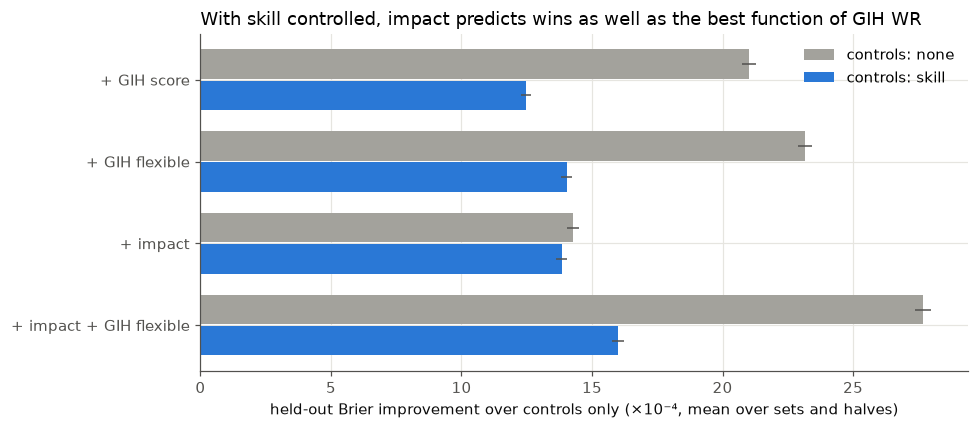

In [11]:
val_pred = pl.read_csv(OUT / "impact_validation_pred.csv")
val_cards = pl.read_csv(OUT / "impact_validation_cards.csv")
MODELS = ["+ GIH score", "+ GIH flexible", "+ impact", "+ impact + GIH flexible"]

pred_tbl = (val_pred.filter(pl.col("model") != "controls only")
            .group_by("controls", "model")
            .agg((pl.col("d_brier").mean() * 1e4).alias("Δ Brier ×1e4"),
                 (pl.col("se_d_brier").pow(2).sum().sqrt() / pl.len() * 1e4).alias("se"),
                 (pl.col("d_logloss").mean() * 1e4).alias("Δ log loss ×1e4"))
            .sort("controls", pl.col("model").replace_strict({m: i for i, m in enumerate(MODELS)})))
display(pred_tbl)
wide = val_pred.pivot(on="model", index=["set", "fit_half", "controls"], values="d_brier")
display(wide.group_by("controls").agg(
    (pl.col("+ impact") < pl.col("+ GIH score")).mean().alias("impact beats GIH score"),
    (pl.col("+ impact") < pl.col("+ GIH flexible")).mean().alias("impact beats GIH flexible"),
    ((pl.col("+ impact + GIH flexible") - pl.col("+ GIH flexible")) * 1e4).mean().alias("impact adds to flexible"),
    ((pl.col("+ impact + GIH flexible") - pl.col("+ impact")) * 1e4).mean().alias("flexible adds to impact"))
    .sort("controls"))
print("share of the 38 set × half fits; the last two columns are mean Δ Brier ×1e4 from adding the other term")

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(MODELS))
for k, (cs, c) in enumerate([("none", GRAY), ("skill", BLUE)]):
    d = {r["model"]: r for r in pred_tbl.filter(pl.col("controls") == cs).iter_rows(named=True)}
    v = [-d[m]["Δ Brier ×1e4"] for m in MODELS]
    ax.barh(y + (k - 0.5) * 0.38, v, height=0.36, color=c, label=f"controls: {cs}",
            xerr=[1.96 * d[m]["se"] for m in MODELS], error_kw={"ecolor": MUTED, "lw": 1})
ax.set_yticks(y, MODELS); ax.invert_yaxis()
ax.set_xlabel("held-out Brier improvement over controls only (×10⁻⁴, mean over sets and halves)")
ax.set_title("With skill controlled, impact predicts wins as well as the best function of GIH WR", loc="left")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [12]:
def dm(c, by=("set", "rarity")):
    return (pl.col(c) - pl.col(c).mean().over(*by)).alias(c)


vc = val_cards.with_columns(*[dm(c) for c in ["gih_0", "gih_1", "beta_0", "beta_1"]])
rows = []
for r in RARITIES + [None]:
    d = vc if r is None else vc.filter(pl.col("rarity") == r)
    cor = lambda a, b: pearsonr(d[a], d[b])[0]
    rg, rb = cor("gih_0", "gih_1"), cor("beta_0", "beta_1")
    cross = (cor("gih_0", "beta_1") + cor("gih_1", "beta_0")) / 2
    z = (d["beta_0"] - d["beta_1"]) / (d["se_0"] ** 2 + d["se_1"] ** 2).sqrt()
    rows.append({"rarity": r or "all", "cards": d.height, "reliability GIH": rg, "reliability impact": rb,
                 "r across halves": cross, "r without noise": cross / np.sqrt(rg * rb), "SD of z (impact)": z.std()})
rel_tbl = pl.DataFrame(rows)
display(rel_tbl)
print("within set × rarity, pooled over sets. SD of z: (β_A − β_B) / √(se_A² + se_B²), 1 if the clustered SEs are right")

rarity,cards,reliability GIH,reliability impact,r across halves,r without noise,SD of z (impact)
str,i64,f64,f64,f64,f64,f64
"""common""",1779,0.95,0.73,0.39,0.47,1.00
"""uncommon""",1894,0.96,0.78,0.65,0.76,1.02
"""rare""",1281,0.95,0.82,0.81,0.92,1.00
"""mythic""",492,0.93,0.82,0.82,0.94,1.00
"""all""",5446,0.95,0.80,0.72,0.82,1.01


within set × rarity, pooled over sets. SD of z: (β_A − β_B) / √(se_A² + se_B²), 1 if the clustered SEs are right


rarity,cards,r impact,"r impact, no skill control (spec A)",r GIH rating
str,i64,f64,f64,f64
"""common""",1741,0.43,0.29,0.32
"""uncommon""",1789,0.52,0.40,0.50
"""rare""",1129,0.68,0.55,0.68
"""mythic""",390,0.71,0.61,0.71
"""all""",5049,0.63,0.49,0.61


correlation with the card's Sealed impact (within set); median Sealed SE 0.70 pp, 0.94M Sealed games


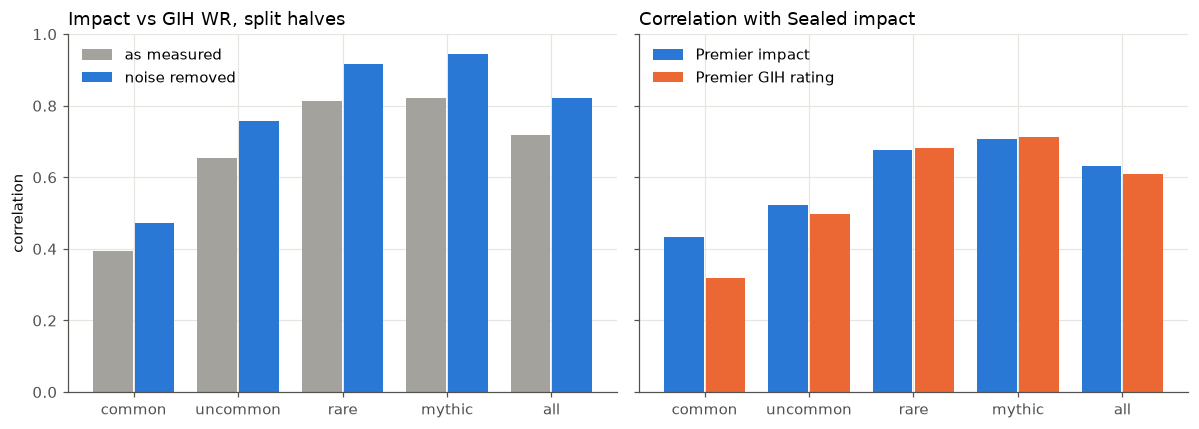

In [13]:
sl = (val_cards.join(imp.select("set", "name", "impact", "impact_eb_A", "norm_eb"), on=["set", "name"])
      .filter(pl.col("sealed_games_in_deck") >= 500))
s_d = sl.with_columns(*[dm(c, ("set",)) for c in ["impact", "impact_eb_A", "norm_eb", "sealed_beta"]])
rows = []
for r in RARITIES + [None]:
    d = s_d if r is None else s_d.filter(pl.col("rarity") == r)
    cor = lambda a: pearsonr(d[a], d["sealed_beta"])[0]
    rows.append({"rarity": r or "all", "cards": d.height, "r impact": cor("impact"),
                 "r impact, no skill control (spec A)": cor("impact_eb_A"), "r GIH rating": cor("norm_eb")})
sealed_tbl = pl.DataFrame(rows)
display(sealed_tbl)
print(f"correlation with the card's Sealed impact (within set); median Sealed SE {sl['sealed_se'].median():.2f} pp, "
      f"{sl['sealed_games'].unique().sum() / 1e6:.2f}M Sealed games")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(RARITIES) + 1)
labs = RARITIES + ["all"]
ax = axes[0]
ax.bar(x - 0.2, rel_tbl["r across halves"], width=0.38, color=GRAY, label="as measured")
ax.bar(x + 0.2, rel_tbl["r without noise"], width=0.38, color=BLUE, label="noise removed")
ax.set_xticks(x, labs); ax.set_ylabel("correlation"); ax.set_ylim(0, 1)
ax.set_title("Impact vs GIH WR, split halves", loc="left"); ax.legend(loc="upper left")
ax = axes[1]
ax.bar(x - 0.2, sealed_tbl["r impact"], width=0.38, color=BLUE, label="Premier impact")
ax.bar(x + 0.2, sealed_tbl["r GIH rating"], width=0.38, color=ORANGE, label="Premier GIH rating")
ax.set_xticks(x, labs)
ax.set_title("Correlation with Sealed impact", loc="left"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

skill_in_deck: r with residual = -0.33, r with spec A − spec B = +0.26
mana_value: r with residual = -0.03, r with spec A − spec B = -0.07


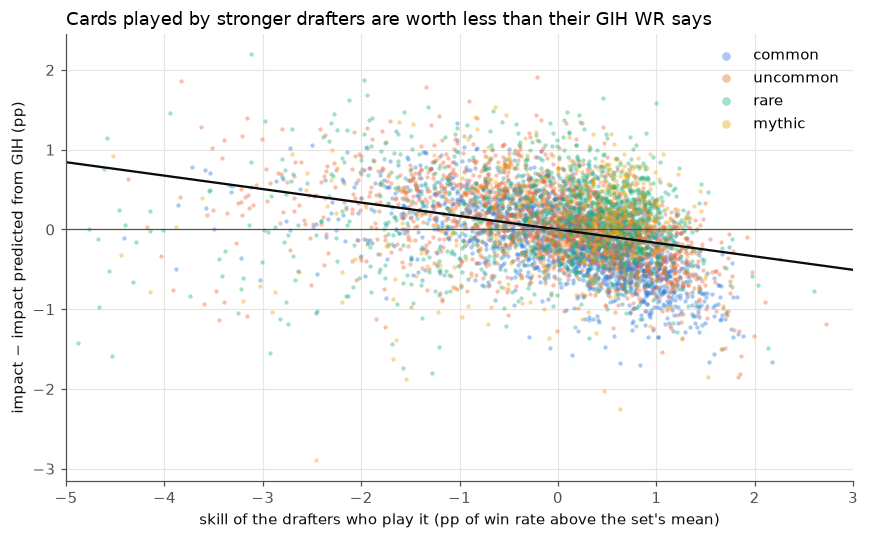

In [14]:
parts = []
for s in SETS:
    d = val_cards.join(imp.select("set", "name", "impact", "norm_eb", "beta_A", "beta_B"), on=["set", "name"]).filter(
        pl.col("set") == s)
    co = np.polyfit(d["norm_eb"], d["impact"], 2)
    parts.append(d.with_columns(pl.Series("resid", d["impact"].to_numpy() - np.polyval(co, d["norm_eb"].to_numpy()))))
resid = pl.concat(parts).with_columns(dm("skill_in_deck", ("set",)), (pl.col("beta_A") - pl.col("beta_B")).alias("A − B"))
for k in ["skill_in_deck", "mana_value"]:
    d = resid.filter(pl.col(k).is_not_null())
    print(f"{k}: r with residual = {pearsonr(d[k], d['resid'])[0]:+.2f}, r with spec A − spec B = "
          f"{pearsonr(d[k], d['A − B'])[0]:+.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
for r in RARITIES:
    d = resid.filter(pl.col("rarity") == r)
    ax.scatter(d["skill_in_deck"], d["resid"], s=8, alpha=0.4, color=R_COLOR[r], lw=0, label=r)
b = np.polyfit(resid["skill_in_deck"], resid["resid"], 1)
ax.set_xlim(-5, 3)
xs = np.array(ax.get_xlim())
ax.plot(xs, np.polyval(b, xs), color=INK, lw=1.5)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("skill of the drafters who play it (pp of win rate above the set's mean)")
ax.set_ylabel("impact − impact predicted from GIH (pp)")
ax.set_title("Cards played by stronger drafters are worth less than their GIH WR says", loc="left")
ax.legend(markerscale=2)
plt.tight_layout(); plt.show()

**What it shows.**
* **Prediction.** Once drafter skill is controlled, a deck's total impact predicts held-out wins as well as the best
  function of GIH WR (Δ Brier −13.8 vs −14.0 ×10⁻⁴; impact wins 17 of 38 fits) and better than the linear GIH deck
  score (−12.5; impact wins 35 of 38). The two carry some different information: adding either one to the other
  improves the fit by about 2 more. Without the skill controls, GIH WR predicts much better (−23 vs −14) because it
  carries the drafter's skill: good drafters' decks are full of cards with high GIH WR. That's what impact is built
  to remove, so for "which deck is stronger" GIH WR wins, and for "what is this card worth" it overstates.
* **Noise.** The clustered SEs are right (the SD of z is 1.00). GIH WR is far more reliable from half to half (0.95) than
  impact (0.80), because impact is a regression with more to estimate. Removing the noise lifts the impact–GIH
  correlation from 0.72 to 0.82 overall and to 0.92–0.94 for rares and mythics, but only to 0.47 for commons. So the
  low agreement for commons in 4b is mostly not noise. The two measures really do rank commons differently.
* **Sealed.** Premier impact predicts a card's Sealed impact a little better than its GIH rating (r = 0.63 vs 0.61),
  clearly better for commons (0.43 vs 0.32), and equally for rares and mythics. Impact without the skill control
  (spec A) does worst (0.49), so the skill control is doing real work. One caveat: the Sealed side uses the same
  regression method, so it shares any blind spots impact has.
* **Where they disagree.** Cards played by stronger drafters have lower impact than their GIH WR predicts (r = −0.33).
  That's the bias impact is built to remove. Mana value has nothing to do with the gap (r = −0.03).
* **Overall.** Impact and GIH WR agree on the cards that matter for bombs (rares and mythics, r ≈ 0.93 without noise).
  Impact is a better measure of what a card is worth, and the gain is concentrated in commons and uncommons, where
  skill selection is a big part of GIH WR.


## 5. Prince or pauper?

Limited players sort formats on a prince–pauper axis:

* A **prince** format is decided by rares. Commons and uncommons are fairly flat in power, and many rares must be
  answered or you lose. The textbook examples are Theros Beyond Death and Innistrad: Crimson Vow (neither is in our data).
* A **pauper** format is decided by commons and uncommons: synergy, tempo, and efficient common answers to big threats.

**Prince isn't the same as bomb-heavy.** Bomb-heavy is about the *count* of game-winning cards (section 4). Prince is
about where the *difference between decks* comes from. A set can have many bombs and also deep, strong commons and
uncommons. Then rares are only part of what separates a good deck from a bad one, and the set is bomb-heavy but not
prince. A set can also have few true bombs but very flat commons. Then the rares you open are still what separates
decks, so it's prince without being bomb-heavy.

**The index** (`scripts/prince_index.py`, `results/bombs/prince_index.csv`). Each card's value is its section 4
`impact`: pp of game win rate per copy compared with an average card of the same deck. For every Premier Draft deck:
* $V$ = the sum of its cards' values,
* $R$ = the part of $V$ from rares and mythics.

The **rare share** is $\mathrm{Cov}(R, V) / \mathrm{Var}(V)$: the share of the between-deck variance in card value
that comes from rares and mythics. It and the commons-and-uncommons share add to 1.

Labels, relative to these 19 sets: **prince** at rare share ≥ 0.36, **pauper** at ≤ 0.28, **middle** in between. Neighboring
sets often differ by 0.01, so treat the borders as soft. And with no THB or VOW in the data to anchor the scale,
"prince" means "the most rare-driven of these 19 sets".

Other columns:
* `rares/deck`: rares and mythics per deck. Play Boosters (MKM onward) put more rares in packs, which raises the
  rare share by itself.
* `top-10 R/M`, `top-10 C/U`: mean value of the set's 10 best rares/mythics and 10 best commons/uncommons.
* `top gap`: their difference.
* `sd C/U`: the spread of value among commons and uncommons. Low means flat.
* `bombs`: section 4's count of cards ≥ 2.5 pp.

In [15]:
prince = pl.read_csv(OUT / "prince_index.csv")
tier = pl.when(pl.col("rarity").is_in(["rare", "mythic"])).then(pl.lit("RM")).when(
    pl.col("rarity").is_in(["common", "uncommon"])).then(pl.lit("CU")).otherwise(None)
card_side = (imp.with_columns(tier.alias("tier")).filter(pl.col("tier").is_not_null())
             .group_by("set", "tier").agg(pl.col("impact").sort(descending=True).head(10).mean().alias("top10"),
                                          pl.col("impact").std().alias("sd"))
             .pivot(on="tier", index="set", values=["top10", "sd"]))
pp = (prince.join(card_side, on="set").join(impact_tbl.select("set", "bombs"), on="set")
      .with_columns((pl.col("top10_RM") - pl.col("top10_CU")).alias("top gap"),
                    pl.when(pl.col("rare_share") >= 0.36).then(pl.lit("prince"))
                    .when(pl.col("rare_share") <= 0.28).then(pl.lit("pauper")).otherwise(pl.lit("middle")).alias("label"))
      .sort("rare_share", descending=True)
      .select("set", "label", pl.col("rare_share").alias("rare share"), pl.col("rares per deck").alias("rares/deck"),
              pl.col("top10_RM").alias("top-10 R/M"), pl.col("top10_CU").alias("top-10 C/U"), "top gap",
              pl.col("sd_CU").alias("sd C/U"), "bombs", pl.col("sd deck value").alias("sd deck value")))
pp.write_csv(OUT / "prince_pauper.csv")
display(pp)
print({k: pp.filter(pl.col("label") == k)["set"].to_list() for k in ["prince", "middle", "pauper"]})

set,label,rare share,rares/deck,top-10 R/M,top-10 C/U,top gap,sd C/U,bombs,sd deck value
str,str,f64,f64,f64,f64,f64,f64,i64,f64
"""TLA""","""prince""",0.43,2.82,3.36,1.07,2.29,0.52,10,3.92
"""TDM""","""prince""",0.41,2.92,3.91,0.82,3.08,0.51,10,4.24
"""MKM""","""prince""",0.40,2.79,2.98,1.09,1.89,0.60,8,3.68
"""DSK""","""prince""",0.39,2.33,3.36,1.34,2.02,0.63,10,3.92
"""OTJ""","""prince""",0.38,2.98,3.10,1.09,2.01,0.59,10,3.66
"""MSH""","""prince""",0.37,2.73,3.07,0.95,2.12,0.48,7,3.83
"""EOE""","""middle""",0.35,2.50,2.49,1.00,1.49,0.50,3,3.45
"""WOE""","""middle""",0.34,2.29,2.84,0.99,1.85,0.57,5,3.51
"""ECL""","""middle""",0.31,2.92,3.27,1.90,1.37,0.74,12,4.95


{'prince': ['TLA', 'TDM', 'MKM', 'DSK', 'OTJ', 'MSH'], 'middle': ['EOE', 'WOE', 'ECL', 'DFT', 'LCI', 'MOM', 'TMT'], 'pauper': ['BLB', 'FDN', 'SOS', 'FIN', 'ONE', 'NEO']}


### 5a. Prince vs bomb-heavy

Each set by its bomb count (section 4) and its rare share. The dashed lines are the medians, which split the sets into four kinds:

* top right: prince *and* bomb-heavy,
* bottom right: bomb-heavy, but commons and uncommons keep up,
* top left: prince with few true bombs (flat commons, so rares still separate decks),
* bottom left: neither.

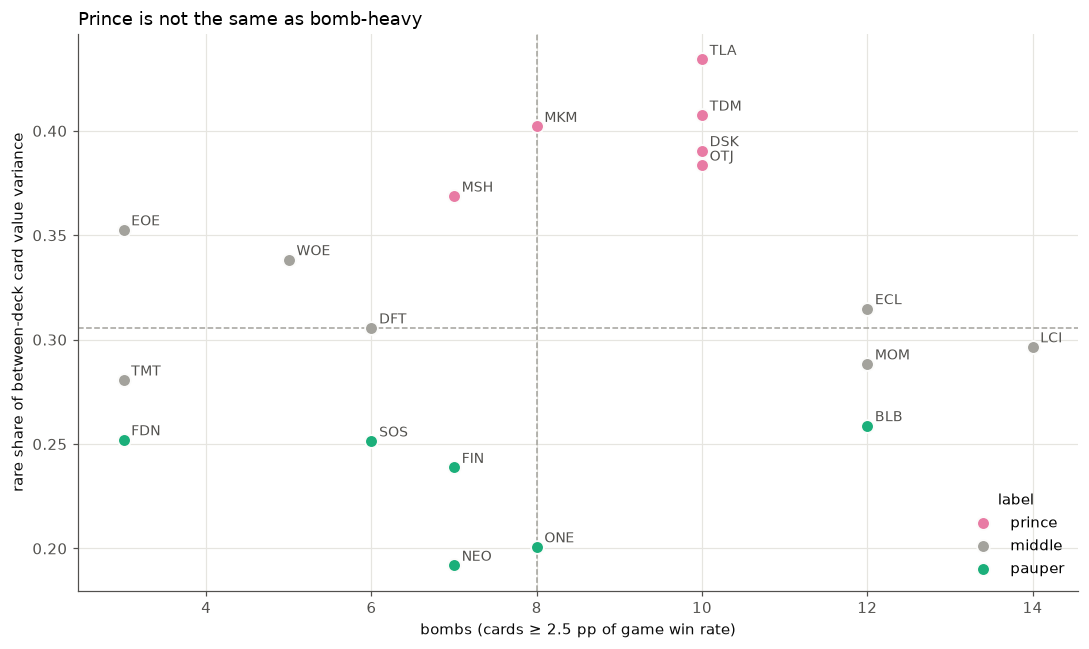

across sets, r(bombs, rare share) = +0.19


In [16]:
LCOL = {"prince": MAGENTA, "middle": GRAY, "pauper": AQUA}
fig, ax = plt.subplots(figsize=(10, 6))
for lab, c in LCOL.items():
    d = pp.filter(pl.col("label") == lab)
    ax.scatter(d["bombs"], d["rare share"], s=70, color=c, edgecolor=SURFACE, lw=1.2, zorder=3, label=lab)
for s, x_, y_ in zip(pp["set"], pp["bombs"], pp["rare share"]):
    ax.annotate(s, (x_, y_), xytext=(5, 3), textcoords="offset points", fontsize=9, color=MUTED)
ax.axvline(pp["bombs"].median(), color=GRAY, ls="--", lw=1); ax.axhline(pp["rare share"].median(), color=GRAY, ls="--", lw=1)
ax.set_xlabel(f"bombs (cards ≥ {IMPACT_BOMB} pp of game win rate)")
ax.set_ylabel("rare share of between-deck card value variance")
ax.set_title("Prince is not the same as bomb-heavy", loc="left"); ax.legend(title="label", loc="lower right")
plt.tight_layout(); plt.show()
print(f"across sets, r(bombs, rare share) = {np.corrcoef(pp['bombs'], pp['rare share'])[0, 1]:+.2f}")

### 5b. What makes a set prince?

The correlation, across the 19 sets, of the rare share with each component. If prince-ness were simply "rares are
stronger than commons", it would track how much better the typical *played* rare is than the typical played common
or uncommon (`played gap`, weighted by how often each card makes a deck).

In [17]:
played = (imp.with_columns(tier.alias("tier")).filter(pl.col("tier").is_not_null())
          .group_by("set", "tier").agg(((pl.col("impact") * pl.col("games_in_deck")).sum() / pl.col("games_in_deck").sum()).alias("m"))
          .pivot(on="tier", index="set", values="m").with_columns((pl.col("RM") - pl.col("CU")).alias("played gap")))
q = pp.join(played.select("set", "played gap"), on="set")
comp = pl.DataFrame([{"component": c, "r with rare share": np.corrcoef(q["rare share"], q[c])[0, 1]}
                     for c in ["played gap", "top gap", "top-10 R/M", "top-10 C/U", "sd C/U", "rares/deck", "bombs"]])
with pl.Config(float_precision=2):
    display(comp)

component,r with rare share
str,f64
"""played gap""",0.16
"""top gap""",0.67
"""top-10 R/M""",0.38
"""top-10 C/U""",-0.50
"""sd C/U""",-0.64
"""rares/deck""",0.49
"""bombs""",0.19


## 6. Deep or shallow?

A **deep** format has more good playables than deck slots: the last cards into a deck are about as good as the rest,
and real playables sit on the bench. In a **shallow** one, drafters run out and fill their decks with cards well below
their average. Depth is about supply against the ~16 nonland slots a deck has. It isn't the same as flatness
(`sd C/U`): a set can have a wide spread of card values and still enough good ones to go around.

**Two measures** (`scripts/depth_index.py`, `results/bombs/depth_index.csv`), both from section 4's `impact`, lands
left out, one row per Premier Draft game:
* `filler gap (sd)`: the mean value of a deck's cards minus the mean of its 3 weakest card copies, divided by the SD
  of value over the set's played cards. Unscaled, the gap mostly tracks how spread out card values are (r = 0.82 with
  `sd C/U`). Scaled, it says how far into the tail decks reach. Small = deep.
* `cuts`: copies of on-color cards (within the deck's main + splash colors) left in the drafter's pool that are worth
  at least the deck's 3rd-weakest card. Large = deep. Pools come from the draft logs (not NEO, ONE) and are cut to the
  first 13 picks of each pack, because pack sizes range from 13 to 15 picks and a bigger pool has a bigger bench.

The **depth index** is the mean of z(`cuts`) and −z(`filler gap (sd)`) across sets (NEO and ONE: the gap alone).
Labels are relative to these 19 sets: the top 6 are **deep**, the bottom 6 **shallow**. Using the 5 weakest
copies instead of 3 gives nearly the same order (Spearman 0.97 for the gap, 0.94 for cuts).


In [18]:
depth = pl.read_csv(OUT / "depth_index.csv")
z = lambda c: (pl.col(c) - pl.col(c).mean()) / pl.col(c).std()
depth = (depth.with_columns(pl.mean_horizontal(z("cuts"), -z("filler gap (sd)")).alias("depth index"))
         .sort("depth index", descending=True)
         .with_columns(pl.int_range(pl.len()).alias("rk"))
         .with_columns(pl.when(pl.col("rk") < 6).then(pl.lit("deep")).when(pl.col("rk") >= pl.len() - 6)
                       .then(pl.lit("shallow")).otherwise(pl.lit("middle")).alias("depth"))
         .join(pp.select("set", "label", "rare share", "sd C/U", "bombs"), on="set")
         .sort("depth index", descending=True)
         .select("set", "depth", "depth index", "filler gap", "filler gap (sd)", "cuts", "P(cuts ≥1)", "label",
                 "rare share", "sd C/U", "bombs"))
depth.write_csv(OUT / "deep_shallow.csv")
display(depth)
print({k: depth.filter(pl.col("depth") == k)["set"].to_list() for k in ["deep", "middle", "shallow"]})
m = depth.drop_nulls("cuts")
print(f"r(cuts, filler gap (sd)) = {np.corrcoef(m['cuts'], m['filler gap (sd)'])[0, 1]:+.2f} over {m.height} sets")


set,depth,depth index,filler gap,filler gap (sd),cuts,P(cuts ≥1),label,rare share,sd C/U,bombs
str,str,f64,f64,f64,f64,f64,str,f64,f64,i64
"""ECL""","""deep""",1.72,1.00,1.08,7.60,1.00,"""middle""",0.31,0.74,12
"""TMT""","""deep""",0.82,0.77,1.12,6.73,0.99,"""middle""",0.28,0.54,3
"""TLA""","""deep""",0.81,0.88,1.12,6.67,0.99,"""prince""",0.43,0.52,10
"""WOE""","""deep""",0.66,0.86,1.26,7.78,0.99,"""middle""",0.34,0.57,5
"""LCI""","""deep""",0.54,1.02,1.16,6.73,0.99,"""middle""",0.30,0.65,14
"""TDM""","""deep""",0.41,0.86,1.09,5.93,0.99,"""prince""",0.41,0.51,10
"""MSH""","""middle""",0.37,0.88,1.22,6.99,0.99,"""prince""",0.37,0.48,7
"""MOM""","""middle""",0.27,1.02,1.19,6.66,0.99,"""middle""",0.29,0.65,12
"""EOE""","""middle""",0.13,0.77,1.22,6.68,0.99,"""middle""",0.35,0.50,3


{'deep': ['ECL', 'TMT', 'TLA', 'WOE', 'LCI', 'TDM'], 'middle': ['MSH', 'MOM', 'EOE', 'DSK', 'DFT', 'MKM', 'NEO'], 'shallow': ['BLB', 'SOS', 'OTJ', 'ONE', 'FDN', 'FIN']}
r(cuts, filler gap (sd)) = -0.34 over 17 sets


### 6a. Deep vs prince

Each set by its depth index and its rare share (section 5), colored by the prince/pauper label.


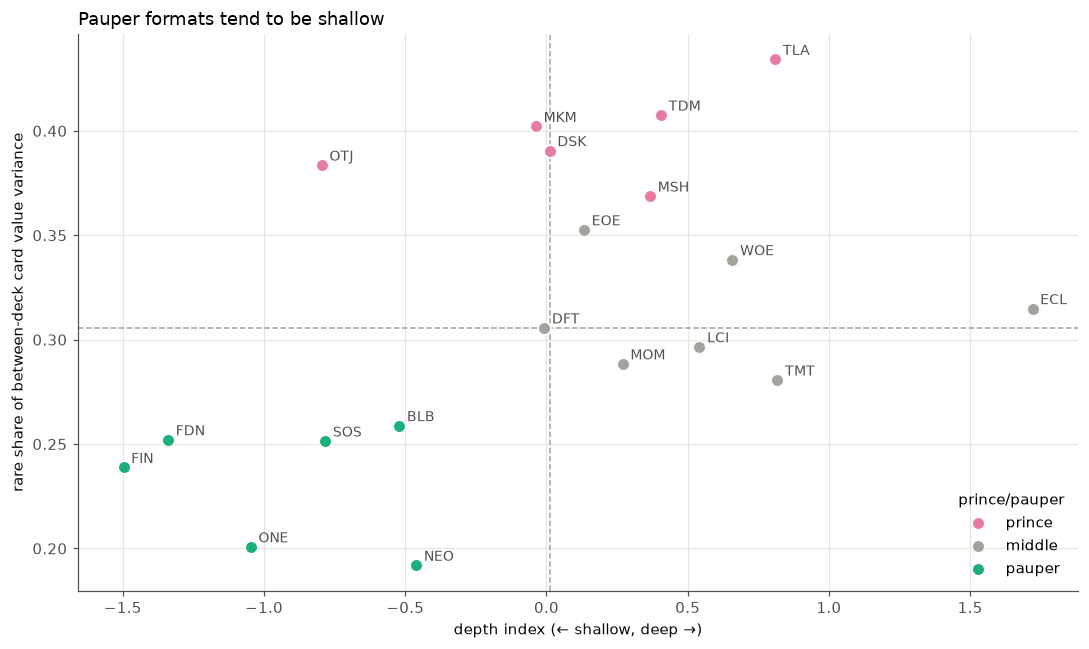

component,r with depth index
str,f64
"""rare share""",0.49
"""sd C/U""",-0.22
"""bombs""",0.27


In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
for lab, c in LCOL.items():
    d = depth.filter(pl.col("label") == lab)
    ax.scatter(d["depth index"], d["rare share"], s=70, color=c, edgecolor=SURFACE, lw=1.2, zorder=3, label=lab)
for s, x_, y_ in zip(depth["set"], depth["depth index"], depth["rare share"]):
    ax.annotate(s, (x_, y_), xytext=(5, 3), textcoords="offset points", fontsize=9, color=MUTED)
ax.axvline(depth["depth index"].median(), color=GRAY, ls="--", lw=1)
ax.axhline(depth["rare share"].median(), color=GRAY, ls="--", lw=1)
ax.set_xlabel("depth index (← shallow, deep →)"); ax.set_ylabel("rare share of between-deck card value variance")
ax.set_title("Pauper formats tend to be shallow", loc="left"); ax.legend(title="prince/pauper", loc="lower right")
plt.tight_layout(); plt.show()
comp = pl.DataFrame([{"component": c, "r with depth index": np.corrcoef(depth["depth index"], depth[c])[0, 1]}
                     for c in ["rare share", "sd C/U", "bombs"]])
with pl.Config(float_precision=2):
    display(comp)


**What it shows.**
* The two measures agree only loosely (r = −0.34 over 17 sets), and the spread between sets is small: filler gap
  1.08–1.33 SD, cuts 5.5–7.8 per deck. Drafters almost always have spare on-color playables (`P(cuts ≥1)` ≈ 98–100%).
  So no set here is shallow in the sense of decks running out of cards. The difference is how good the last few are.
* Shallow: FIN, FDN, ONE, OTJ, SOS, BLB. Deep: ECL, TMT, TLA, WOE, LCI, TDM.
* **Pauper formats tend to be shallow** (r = +0.49 between depth and rare share). Five of the six pauper sets are
  shallow, NEO is middle. When decks have to fill out with weak commons, which commons and uncommons you got is a
  big part of the difference between decks. Part of this may be mechanical, since a deeper reach into C/U filler adds
  C/U variance to deck value.
* Depth isn't flatness or bomb count: r = −0.22 with `sd C/U` and +0.27 with bombs. ECL has the widest C/U spread and
  12 bombs, and is still the deepest set.
